# TP 2 — Deep Learning : pipeline complet sur Tiny Shakespeare

**Tâche** : *attribution d'auteur de réplique* — à partir du texte d'une réplique, prédire **quel personnage parle** parmi 7 personnages principaux (un par pièce).

C'est une vraie tâche de classification supervisée : les labels (`NOM:`) sont fournis par le corpus lui-même.

| Étape | Contenu |
|---|---|
| 1 | Nettoyage & prétraitement : parsing, filtrage, déduplication, split stratifié |
| 2 | Représentation : TF-IDF mots / caractères, embeddings appris |
| 3 | Comparaison **ML** (NB, régression logistique, SVM) vs **DL** (MLP, fastText, BiLSTM, CNN) |
| 4 | Évaluation : accuracy, précision, rappel, F1 macro, balanced accuracy, matrices de confusion, analyse d'erreurs |

In [1]:
import time, warnings
import matplotlib.pyplot as plt
import seaborn as sns
import torch, torch.nn as nn, torch.nn.functional as F
warnings.filterwarnings("ignore")
torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


## 1. Nettoyage & prétraitement

### 1.1 Parsing, filtrage, split

In [2]:
import os, re, random
import numpy as np
import pandas as pd
from urllib.request import urlretrieve
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)

if not os.path.exists("input.txt"):
    urlretrieve("https://raw.githubusercontent.com/karpathy/char-rnn/master/"
                "data/tinyshakespeare/input.txt", "input.txt")
with open("input.txt", encoding="utf-8") as f:
    raw = f.read()

# 1 réplique = un bloc séparé par une ligne vide : "NOM:\ntexte..."
records = []
for block in raw.strip().split("\n\n"):
    lines = block.split("\n")
    if len(lines) > 1 and re.fullmatch(r"[A-Z][A-Za-z' .-]*:", lines[0]):
        records.append({"speaker": lines[0][:-1], "text": " ".join(l.strip() for l in lines[1:])})
df_all = pd.DataFrame(records)

# 7 personnages, chacun d'une pièce différente
PLAYS = {
    "GLOUCESTER": "Richard III / Henry VI (Richard, duc de Gloucester)",
    "DUKE VINCENTIO": "Measure for Measure",
    "MENENIUS": "Coriolanus",
    "ROMEO": "Romeo and Juliet",
    "PETRUCHIO": "The Taming of the Shrew",
    "LEONTES": "The Winter's Tale",
    "KING RICHARD II": "Richard II",
}
LABELS = list(PLAYS)
df = df_all[df_all.speaker.isin(LABELS)].copy()
df["text"] = df.text.str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df.text.str.split().str.len() >= 3]                 # répliques trop courtes : pas de signal
df = df.drop_duplicates("text").reset_index(drop=True)       # dédupliquer AVANT le split
df["label"] = df.speaker.map({s: i for i, s in enumerate(LABELS)})

# split stratifié 70 / 15 / 15
train_df, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
print(f"{len(df_all)} répliques au total -> {len(df)} retenues | train {len(train_df)} / val {len(val_df)} / test {len(test_df)}")

7093 répliques au total -> 1066 retenues | train 746 / val 160 / test 160


In [3]:
print(df_all.speaker.value_counts().head(10), "\n")
print(df.speaker.value_counts())
df.sample(5, random_state=1)[["speaker", "text"]]

speaker
GLOUCESTER          211
DUKE VINCENTIO      189
MENENIUS            161
ROMEO               160
PETRUCHIO           155
CORIOLANUS          148
KING RICHARD III    137
ISABELLA            127
JULIET              124
LEONTES             124
Name: count, dtype: int64 

speaker
GLOUCESTER         206
DUKE VINCENTIO     184
ROMEO              155
MENENIUS           154
PETRUCHIO          149
LEONTES            120
KING RICHARD II     98
Name: count, dtype: int64


,speaker,text
133,MENENIUS,"Well, and say that Marcius Return me, as Comin..."
340,KING RICHARD II,"Now put it, God, in the physician's mind To he..."
848,DUKE VINCENTIO,"This letter, then, to Friar Peter give; 'Tis t..."
1057,PETRUCHIO,"Where is your sister, and Hortensio's wife?"
756,DUKE VINCENTIO,"Bring me to hear them speak, where I may be co..."


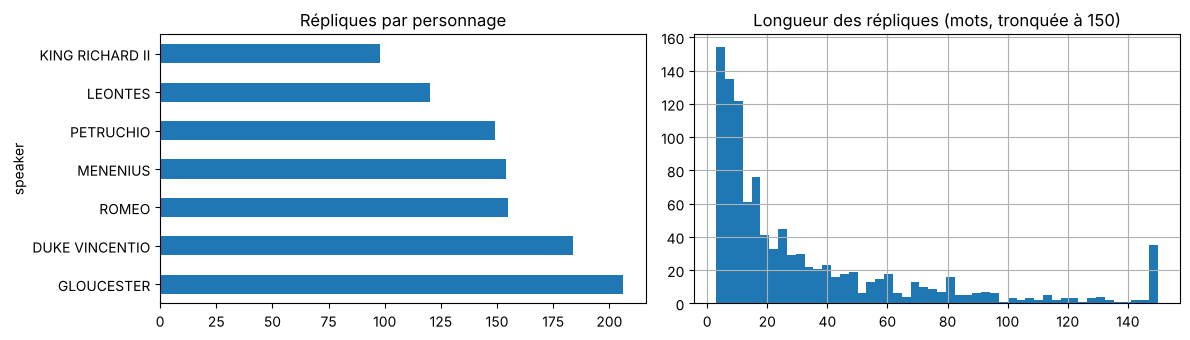

Longueur médiane : 17.0 mots


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
df.speaker.value_counts().plot.barh(ax=ax[0], title="Répliques par personnage")
df.text.str.split().str.len().clip(upper=150).hist(bins=50, ax=ax[1])
ax[1].set_title("Longueur des répliques (mots, tronquée à 150)")
plt.tight_layout(); plt.show()
print("Longueur médiane :", df.text.str.split().str.len().median(), "mots")

**Choix de prétraitement**
- **Unité d'exemple** = une réplique (bloc `NOM:` + texte). La ligne `NOM:` est le **label** ; elle est retirée du texte (sinon fuite évidente).
- **7 personnages de 7 pièces différentes** : assez d'exemples par classe (≈ 100-200) et une tâche non triviale.
- Filtrage des répliques de moins de 3 mots (« Ay. », « What? » : aucun signal).
- **Déduplication avant le split** pour qu'une même réplique ne soit pas en train et en test.
- **Split stratifié 70/15/15** : la validation sert aux choix (hyperparamètres, early stopping), le test n'est utilisé **qu'une fois**, à la fin.
- Déséquilibre modéré (≈ 1,8× entre la plus grosse et la plus petite classe) → on publie des scores **macro** et on teste la pondération des classes.

### 1.2 Normalisation du texte

In [5]:
import string
def clean(s):
    s = s.lower()
    s = re.sub(r"[^a-z' ]+", " ", s)       # garde lettres + apostrophes (thou'rt, 'tis)
    return re.sub(r"\s+", " ", s).strip()

for d in (train_df, val_df, test_df):
    d["clean"] = d.text.map(clean)

y_train, y_val, y_test = train_df.label.values, val_df.label.values, test_df.label.values
print(train_df.text.iloc[0][:200]); print(train_df.clean.iloc[0][:200])

That last is true; the sweeter rest was mine.
that last is true the sweeter rest was mine


On **ne retire pas les stopwords** : chez Shakespeare, *thou / thee / thy / you*, *ay / nay*, *'tis* sont des marqueurs de style et de rapport social très informatifs pour reconnaître un locuteur. Pas de lemmatisation non plus (l'anglais élisabéthain est mal géré par les lemmatiseurs modernes).

In [6]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix)

def scores(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision_macro": p, "recall_macro": r, "f1_macro": f}

## 2. Représentations

### 2.1 Représentations creuses (pour le ML)

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from scipy.sparse import hstack

# fit UNIQUEMENT sur le train (sinon fuite du vocabulaire/IDF du test)
bow = CountVectorizer(ngram_range=(1, 1), min_df=2).fit(train_df.clean)
tfidf_w = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(train_df.clean)
tfidf_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True).fit(train_df.clean)

def feats(texts, kind):
    if kind == "bow":     return bow.transform(texts)
    if kind == "tfidf_w": return tfidf_w.transform(texts)
    if kind == "tfidf_c": return tfidf_c.transform(texts)
    if kind == "tfidf_wc": return hstack([tfidf_w.transform(texts), tfidf_c.transform(texts)]).tocsr()

for k in ("bow", "tfidf_w", "tfidf_c", "tfidf_wc"):
    print(f"{k:9s} -> {feats(train_df.clean, k).shape}")

bow       -> (746, 1832)
tfidf_w   -> (746, 4355)
tfidf_c   -> (746, 11307)


tfidf_wc  -> (746, 15662)


### 2.2 Représentations denses (pour le DL)
Vocabulaire de mots construit sur le train, chaque mot → un entier → un **embedding appris** de dimension 100. Contrairement au TF-IDF, deux mots proches (*king / queen*) peuvent obtenir des vecteurs proches.

In [8]:
from collections import Counter
cnt = Counter(w for s in train_df.clean for w in s.split())
itos = ["<pad>", "<unk>"] + [w for w, c in cnt.most_common() if c >= 2]
stoi = {w: i for i, w in enumerate(itos)}
MAX_LEN = 120                                   # couvre ~95 % des répliques

def encode(s):
    ids = [stoi.get(w, 1) for w in s.split()][:MAX_LEN]
    return ids or [1]

def to_tensor(texts):
    seqs = [encode(s) for s in texts]
    lens = torch.tensor([len(s) for s in seqs])
    X = torch.zeros(len(seqs), MAX_LEN, dtype=torch.long)
    for i, s in enumerate(seqs): X[i, :len(s)] = torch.tensor(s)
    return X, lens

Xtr_seq, Ltr = to_tensor(train_df.clean); Xva_seq, Lva = to_tensor(val_df.clean); Xte_seq, Lte = to_tensor(test_df.clean)
print("vocab :", len(itos), "| tenseur train :", tuple(Xtr_seq.shape))
print("taux d'OOV en test :", round((Xte_seq == 1).sum().item() / (Xte_seq > 0).sum().item(), 3))

vocab : 1937 | tenseur train : (746, 120)
taux d'OOV en test : 0.141


## 3. Modèles

### 3.1 Machine learning classique

In [9]:
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

results = []
def log(name, family, rep, y_pred, split, secs, n_params=None):
    results.append({"modèle": name, "famille": family, "représentation": rep, "split": split,
                    **scores(y_val if split == "val" else y_test, y_pred), "temps_s": secs, "params": n_params})

ml_models = {
    "Naive Bayes":   (lambda: ComplementNB(alpha=0.3), ["bow", "tfidf_w"]),
    "Rég. logistique": (lambda: LogisticRegression(C=10, max_iter=3000, class_weight="balanced"), ["tfidf_w", "tfidf_c", "tfidf_wc"]),
    "SVM linéaire":  (lambda: LinearSVC(C=0.5, class_weight="balanced"), ["tfidf_w", "tfidf_c", "tfidf_wc"]),
}
fitted = {}
for name, (make, reps) in ml_models.items():
    for rep in reps:
        t0 = time.time()
        clf = make().fit(feats(train_df.clean, rep), y_train)
        secs = time.time() - t0
        fitted[(name, rep)] = clf
        log(name, "ML", rep, clf.predict(feats(val_df.clean, rep)), "val", secs)

pd.DataFrame(results).query("split=='val'").sort_values("f1_macro", ascending=False).round(3)

,modèle,famille,représentation,split,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,temps_s,params
6,SVM linéaire,ML,tfidf_c,val,0.619,0.606,0.617,0.606,0.607,0.213,None
7,SVM linéaire,ML,tfidf_wc,val,0.606,0.595,0.607,0.595,0.597,0.256,None
4,Rég. logistique,ML,tfidf_wc,val,0.600,0.588,0.613,0.588,0.595,1.426,None
3,Rég. logistique,ML,tfidf_c,val,0.594,0.574,0.597,0.574,0.577,1.073,None
0,Naive Bayes,ML,bow,val,0.588,0.574,0.578,0.574,0.569,0.016,None
1,Naive Bayes,ML,tfidf_w,val,0.588,0.570,0.567,0.570,0.567,0.027,None
5,SVM linéaire,ML,tfidf_w,val,0.562,0.557,0.556,0.557,0.554,0.026,None
2,Rég. logistique,ML,tfidf_w,val,0.556,0.547,0.549,0.547,0.544,0.666,None


Les hyperparamètres (`C`, `alpha`, n-grammes) ont été choisis en regardant **uniquement la validation**. La pondération `class_weight="balanced"` applique wₖ = N / (K·Nₖ) : une erreur sur une classe rare coûte plus cher.

### 3.2 Deep learning (PyTorch)

Quatre architectures, du plus simple au plus expressif :
- **MLP sur TF-IDF** : même entrée que le ML, mais avec une couche cachée non linéaire ;
- **fastText-like** : moyenne des embeddings de mots → linéaire (un sac de mots *dense*) ;
- **BiLSTM** : lit la réplique dans les deux sens, tient compte de l'ordre ;
- **CNN 1D** : filtres de largeur 2/3/4 = détecteurs de n-grammes appris, puis max-pooling.

Entraînement commun : AdamW, cross-entropy **pondérée** (mêmes poids que `balanced`), **early stopping** sur le F1 macro de validation (patience 5), restauration du meilleur checkpoint.

In [10]:
K = len(LABELS)
cw = torch.tensor(len(y_train) / (K * np.bincount(y_train)), dtype=torch.float32, device=device)

class TfidfMLP(nn.Module):
    def __init__(self, d_in, h=256, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(d_in, h), nn.ReLU(), nn.Dropout(p), nn.Linear(h, K))
    def forward(self, x, lens=None): return self.net(x)

class FastText(nn.Module):
    def __init__(self, V, d=100):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0); self.drop = nn.Dropout(0.3); self.fc = nn.Linear(d, K)
    def forward(self, x, lens):
        e = self.emb(x)                                        # (B,T,d)
        mask = (x > 0).unsqueeze(-1).float()
        return self.fc(self.drop((e * mask).sum(1) / mask.sum(1).clamp(min=1)))

class BiLSTM(nn.Module):
    def __init__(self, V, d=100, h=64):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.lstm = nn.LSTM(d, h, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(0.5); self.fc = nn.Linear(2 * h, K)
    def forward(self, x, lens):
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                          # h: (2,B,h)
        return self.fc(self.drop(torch.cat([h[0], h[1]], -1)))

class TextCNN(nn.Module):
    def __init__(self, V, d=100, nf=64, ks=(2, 3, 4)):
        super().__init__()
        self.emb = nn.Embedding(V, d, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(d, nf, k, padding=k // 2) for k in ks])
        self.drop = nn.Dropout(0.5); self.fc = nn.Linear(nf * len(ks), K)
    def forward(self, x, lens):
        e = self.emb(x).transpose(1, 2)                        # (B,d,T)
        h = torch.cat([F.relu(c(e)).max(-1).values for c in self.convs], -1)
        return self.fc(self.drop(h))

In [11]:
def predict(model, X, L, bs=256):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, X.shape[0], bs):
            out.append(model(X[i:i+bs].to(device), L[i:i+bs]).argmax(-1).cpu())
    return torch.cat(out).numpy()

def train_dl(model, Xtr, Ltr, Xva, Lva, lr=2e-3, wd=1e-4, epochs=60, bs=32, patience=5):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    ytr = torch.tensor(y_train)
    best, best_state, wait, hist = -1, None, 0, []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(ytr)); tot = 0
        for i in range(0, len(perm), bs):
            b = perm[i:i+bs]
            loss = F.cross_entropy(model(Xtr[b].to(device), Ltr[b]), ytr[b].to(device), weight=cw)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(b)
        f1 = f1_score(y_val, predict(model, Xva, Lva), average="macro")
        hist.append((tot / len(ytr), f1))
        if f1 > best: best, best_state, wait = f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(best_state)
    return model, hist

# TF-IDF dense pour le MLP
Xtr_tf = torch.tensor(feats(train_df.clean, "tfidf_w").toarray(), dtype=torch.float32)
Xva_tf = torch.tensor(feats(val_df.clean, "tfidf_w").toarray(), dtype=torch.float32)
Xte_tf = torch.tensor(feats(test_df.clean, "tfidf_w").toarray(), dtype=torch.float32)
dummy = torch.ones(len(Xtr_tf))

V = len(itos)
dl_specs = {
    "MLP (TF-IDF)": (lambda: TfidfMLP(Xtr_tf.shape[1]), "tfidf_w", dict(lr=1e-3, wd=1e-2)),
    "fastText":     (lambda: FastText(V), "embeddings", dict(lr=5e-3)),
    "BiLSTM":       (lambda: BiLSTM(V), "embeddings", dict(lr=2e-3)),
    "CNN 1D":       (lambda: TextCNN(V), "embeddings", dict(lr=1e-3)),
}
data_for = {"tfidf_w": (Xtr_tf, dummy, Xva_tf, torch.ones(len(Xva_tf)), Xte_tf, torch.ones(len(Xte_tf))),
            "embeddings": (Xtr_seq, Ltr, Xva_seq, Lva, Xte_seq, Lte)}

dl_models, histories = {}, {}
for name, (make, rep, hp) in dl_specs.items():
    torch.manual_seed(42)
    Xa, La, Xb, Lb, _, _ = data_for[rep]
    t0 = time.time()
    model, hist = train_dl(make(), Xa, La, Xb, Lb, **hp)
    secs = time.time() - t0
    dl_models[name], histories[name] = model, hist
    n_params = sum(p.numel() for p in model.parameters())
    log(name, "DL", rep, predict(model, Xb, Lb), "val", secs, n_params)
    print(f"{name:13s} | {len(hist):2d} époques | {secs:5.1f}s | {n_params/1e3:7.0f}k params | F1 val {max(h[1] for h in hist):.3f}")

MLP (TF-IDF)  | 14 époques |   3.4s |    1117k params | F1 val 0.611


fastText      | 22 époques |   1.0s |     194k params | F1 val 0.541


BiLSTM        | 15 époques |  21.5s |     280k params | F1 val 0.347


CNN 1D        | 27 époques |  10.7s |     253k params | F1 val 0.463


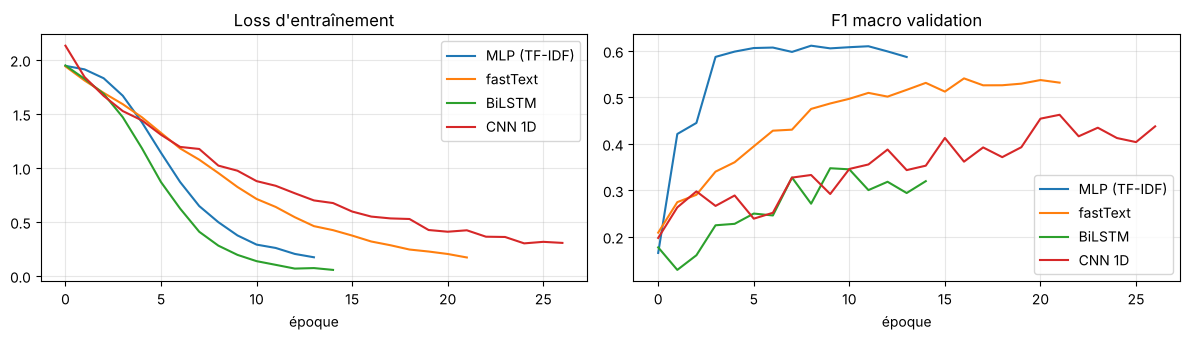

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name, h in histories.items():
    axes[0].plot([a for a, _ in h], label=name); axes[1].plot([b for _, b in h], label=name)
axes[0].set_title("Loss d'entraînement"); axes[1].set_title("F1 macro validation")
for a in axes: a.set_xlabel("époque"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. Évaluation

### 4.1 Comparaison sur la validation

In [13]:
val_table = pd.DataFrame(results).query("split=='val'").drop(columns="split")
val_table.sort_values("f1_macro", ascending=False).round(3).reset_index(drop=True)

,modèle,famille,représentation,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro,temps_s,params
0,MLP (TF-IDF),DL,tfidf_w,0.619,0.614,0.614,0.614,0.611,3.394,1116935.0
1,SVM linéaire,ML,tfidf_c,0.619,0.606,0.617,0.606,0.607,0.213,NaN
2,SVM linéaire,ML,tfidf_wc,0.606,0.595,0.607,0.595,0.597,0.256,NaN
3,Rég. logistique,ML,tfidf_wc,0.600,0.588,0.613,0.588,0.595,1.426,NaN
4,Rég. logistique,ML,tfidf_c,0.594,0.574,0.597,0.574,0.577,1.073,NaN
5,Naive Bayes,ML,bow,0.588,0.574,0.578,0.574,0.569,0.016,NaN
6,Naive Bayes,ML,tfidf_w,0.588,0.570,0.567,0.570,0.567,0.027,NaN
7,SVM linéaire,ML,tfidf_w,0.562,0.557,0.556,0.557,0.554,0.026,NaN
8,Rég. logistique,ML,tfidf_w,0.556,0.547,0.549,0.547,0.544,0.666,NaN
9,fastText,DL,embeddings,0.550,0.545,0.541,0.545,0.541,1.042,194407.0


### 4.2 Évaluation finale sur le test (une seule fois)

On sélectionne **le meilleur modèle ML** et **le meilleur modèle DL** d'après la validation, plus une baseline triviale (classe majoritaire), puis on les évalue sur le test.

In [14]:
from sklearn.dummy import DummyClassifier
best_ml = val_table.query("famille=='ML'").sort_values("f1_macro").iloc[-1]
best_dl = val_table.query("famille=='DL'").sort_values("f1_macro").iloc[-1]
print("Meilleur ML :", best_ml["modèle"], "/", best_ml["représentation"])
print("Meilleur DL :", best_dl["modèle"])

maj = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(y_train), 1)), y_train)
test_preds = {
    "Baseline majoritaire": maj.predict(np.zeros((len(y_test), 1))),
    f"ML — {best_ml['modèle']} ({best_ml['représentation']})": fitted[(best_ml["modèle"], best_ml["représentation"])].predict(feats(test_df.clean, best_ml["représentation"])),
}
_, _, _, _, Xt, Lt = data_for["tfidf_w" if best_dl["modèle"] == "MLP (TF-IDF)" else "embeddings"]
test_preds[f"DL — {best_dl['modèle']}"] = predict(dl_models[best_dl["modèle"]], Xt, Lt)

test_table = pd.DataFrame({k: scores(y_test, v) for k, v in test_preds.items()}).T.round(3)
test_table

Meilleur ML : SVM linéaire / tfidf_c
Meilleur DL : MLP (TF-IDF)


,accuracy,balanced_acc,precision_macro,recall_macro,f1_macro
Baseline majoritaire,0.194,0.143,0.028,0.143,0.046
ML — SVM linéaire (tfidf_c),0.481,0.502,0.479,0.502,0.484
DL — MLP (TF-IDF),0.500,0.505,0.505,0.505,0.500


In [15]:
# Sauvegarde pour la comparaison avec le LLM (TP 3)
os.makedirs("results", exist_ok=True)
test_table.to_csv("results/tp2_test_scores.csv")
pd.DataFrame(results).round(4).to_csv("results/tp2_all_runs.csv", index=False)

### 4.3 Rapport par classe et matrices de confusion

In [16]:
for name, pred in list(test_preds.items())[1:]:
    print("=" * 70, "\n", name)
    print(classification_report(y_test, pred, target_names=LABELS, digits=3, zero_division=0))

 ML — SVM linéaire (tfidf_c)
                 precision    recall  f1-score   support

     GLOUCESTER      0.444     0.258     0.327        31
 DUKE VINCENTIO      0.481     0.464     0.473        28
       MENENIUS      0.409     0.391     0.400        23
          ROMEO      0.467     0.609     0.528        23
      PETRUCHIO      0.609     0.609     0.609        23
        LEONTES      0.524     0.611     0.564        18
KING RICHARD II      0.421     0.571     0.485        14

       accuracy                          0.481       160
      macro avg      0.479     0.502     0.484       160
   weighted avg      0.480     0.481     0.473       160

 DL — MLP (TF-IDF)
                 precision    recall  f1-score   support

     GLOUCESTER      0.483     0.452     0.467        31
 DUKE VINCENTIO      0.545     0.429     0.480        28
       MENENIUS      0.647     0.478     0.550        23
          ROMEO      0.444     0.522     0.480        23
      PETRUCHIO      0.556     0.652

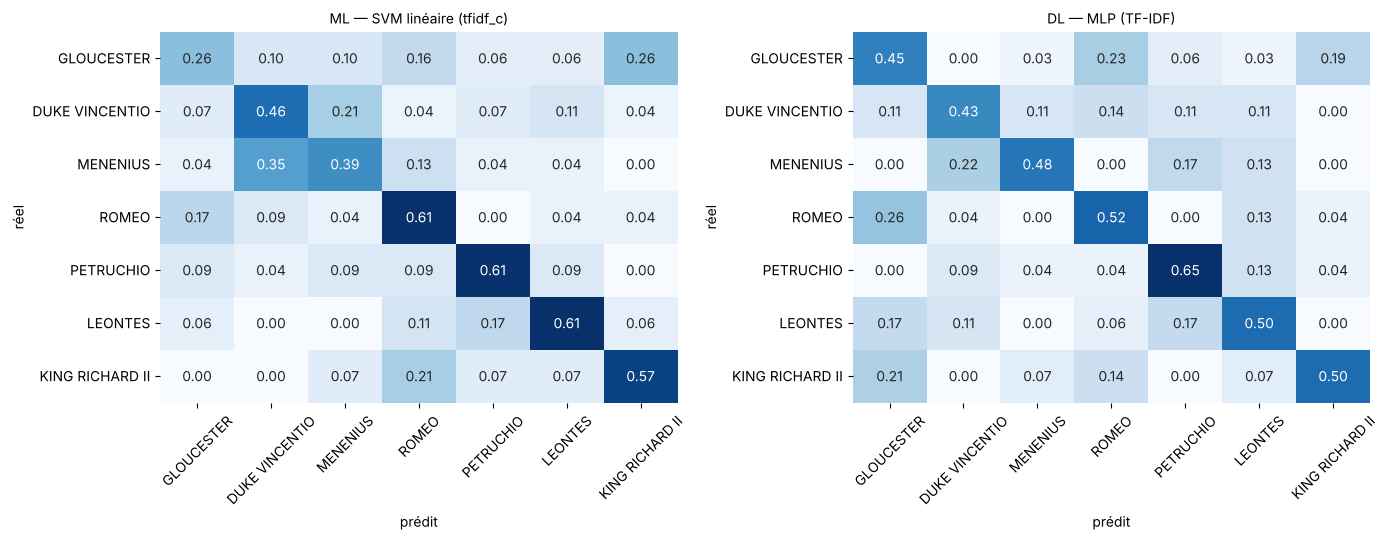

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, pred) in zip(axes, list(test_preds.items())[1:]):
    cm = confusion_matrix(y_test, pred, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=ax, cbar=False)
    ax.set_title(name, fontsize=10); ax.set_xlabel("prédit"); ax.set_ylabel("réel")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

### 4.4 Interprétabilité : ce que le modèle linéaire a appris

In [18]:
lr_w = fitted[("Rég. logistique", "tfidf_w")]
vocab = np.array(tfidf_w.get_feature_names_out())
for k, name in enumerate(LABELS):
    top = vocab[np.argsort(lr_w.coef_[k])[-10:][::-1]]
    print(f"{name:16s}: {', '.join(top)}")

GLOUCESTER      : lord, clarence, edward, brother, marry, my lord, wherefore, myself, place, warwick
DUKE VINCENTIO  : you, provost, angelo, sir, claudio, your, duke, knowledge, ere, barnardine
MENENIUS        : noble, marcius, tribunes, fellow, general, gods, rome, coriolanus, like, has
ROMEO           : love, goose, dream, nurse, light, is my, romeo, that, flower, juliet
PETRUCHIO       : kate, hortensio, there the, me, and, hope, come, mean, first, her
LEONTES         : paulina, read, hold, are married, didst, well said, once, her, as, bohemia
KING RICHARD II : our, king, uncle, cousin, bolingbroke, thou, where lies, we, and shall, say


### 4.5 Analyse d'erreurs

In [19]:
best_ml_pred = list(test_preds.values())[1]
err = test_df.assign(pred=[LABELS[i] for i in best_ml_pred]).query("speaker != pred")
print(f"{len(err)} erreurs / {len(test_df)}")
print("Longueur médiane des répliques bien classées :", test_df[np.array(best_ml_pred) == y_test].text.str.split().str.len().median(), "mots")
print("Longueur médiane des erreurs                 :", err.text.str.split().str.len().median(), "mots\n")
for _, r in err.sample(6, random_state=0).iterrows():
    print(f"[réel {r.speaker} | prédit {r.pred}] {r.text[:160]}")

83 erreurs / 160
Longueur médiane des répliques bien classées : 32.0 mots
Longueur médiane des erreurs                 : 12.0 mots

[réel DUKE VINCENTIO | prédit MENENIUS] Silence that fellow: I would he had some cause To prattle for himself.
[réel GLOUCESTER | prédit DUKE VINCENTIO] It is too heavy for your grace to wear.
[réel DUKE VINCENTIO | prédit KING RICHARD II] For the benefit of silence, would thou wert so too!
[réel LEONTES | prédit KING RICHARD II] I know't too well. Give me the boy: I am glad you did not nurse him: Though he does bear some signs of me, yet you Have too much blood in him.
[réel GLOUCESTER | prédit KING RICHARD II] Madam, have comfort: all of us have cause To wail the dimming of our shining star; But none can cure their harms by wailing them. Madam, my mother, I do cry you
[réel DUKE VINCENTIO | prédit PETRUCHIO] O heavens! what stuff is here


In [20]:
# Accuracy en fonction de la longueur de la réplique
test_df["len_bin"] = pd.cut(test_df.text.str.split().str.len(), [0, 10, 25, 60, 10_000], labels=["≤10", "11-25", "26-60", ">60"])
by_len = pd.DataFrame({name: [accuracy_score(y_test[m], pred[m]) for m in [(test_df.len_bin == b).values for b in test_df.len_bin.cat.categories]]
                       for name, pred in list(test_preds.items())[1:]}, index=test_df.len_bin.cat.categories)
by_len["n"] = test_df.len_bin.value_counts().reindex(by_len.index).values
by_len.round(3)

,ML — SVM linéaire (tfidf_c),DL — MLP (TF-IDF),n
≤10,0.322,0.373,59
11-25,0.395,0.474,38
26-60,0.732,0.707,41
>60,0.591,0.500,22


## Conclusion

*(chiffres obtenus sur CPU, seed 42 — ils peuvent varier légèrement d'une machine à l'autre)*

**ML vs DL**
- Sur la validation, le meilleur **ML** (SVM linéaire sur n-grammes de caractères) atteint un F1 macro ≈ 0,61 en 0,2 s d'entraînement ; le **MLP sur TF-IDF** fait jeu égal (≈ 0,61).
- Sur le **test**, les deux restent au coude à coude (F1 ≈ 0,48 vs 0,50). Avec 160 répliques de test, un écart de 2 points correspond à ~3 répliques : **non significatif**. Le MLP a 1,1 M de paramètres et coûte ~20× plus de temps pour le même résultat.
- Les modèles DL **à embeddings appris** sont nettement en dessous : fastText ≈ 0,54, CNN ≈ 0,46, BiLSTM ≈ 0,35 (val). Avec ≈ 750 répliques d'entraînement et 14 % de mots hors vocabulaire en test, il n'y a pas assez de données pour apprendre de bons embeddings à partir de zéro ; ils sur-apprennent vite (la loss train chute alors que le F1 val plafonne → l'early stopping coupe tôt).
- Le **BiLSTM**, le plus expressif, est le plus lent et le moins bon : l'ordre des mots apporte peu ici. Le signal est surtout **lexical** — noms propres et thèmes de la pièce (*clarence, warwick* pour Gloucester ; *kate, hortensio* pour Petruchio ; *rome, tribunes* pour Menenius ; *bolingbroke, uncle* pour Richard II), ce que montrent les poids de la régression logistique. Les n-grammes de caractères gagnent car ils captent aussi les variantes (*marcius / marcius'*) et les terminaisons (*-est, -eth*).
- La baisse val → test (≈ 0,61 → 0,49) vient de la petite taille des ensembles et du fait que **les choix ont été faits sur la validation** (légère sur-adaptation au jeu de val) : c'est précisément pour ça qu'on garde un test intouché.

**Lecture des erreurs**
- Les erreurs se concentrent sur les **répliques courtes** : longueur médiane 12 mots pour les erreurs contre 32 pour les succès ; accuracy ≈ 0,35 sous 10 mots contre ≈ 0,7 entre 26 et 60 mots. Une réplique comme « O heavens! what stuff is here » ne contient tout simplement aucun indice du personnage.
- Les confusions les plus fréquentes sont entre **personnages de même registre** : les pièces historiques (Gloucester ↔ Richard II, même lexique de la couronne, *madam, grace, cousin*). GLOUCESTER, pourtant la classe la plus fréquente, a le rappel le plus faible pour le SVM : son vocabulaire est le plus « générique ».

**Limites et pistes**
- Le split est aléatoire par réplique : des répliques d'une même scène peuvent être en train et en test (fuite douce via le contexte de scène). Un split **par scène ou par acte** serait plus sévère.
- Pour que le DL dépasse le ML ici, il faudrait **transférer** de la connaissance : embeddings pré-entraînés (GloVe), ou fine-tuning d'un Transformer pré-entraîné (BERT/DistilBERT) — ou utiliser un LLM en prompting, ce qui est l'objet du TP 3.